# Multi-seed sweep and silencing analysis

This notebook combines two kinds of generated artifacts:

- **Sweep collector manifests** (`sweep_archive_*/manifest.json`) for conventional selected scores.
- **Silencing counterfactual directories** (`silencing_*`) for intervention statistics and figures.

Both inputs accept lists, so they may be one combined two-seed directory or separate directories for each seed. The configuration cell also supports including/excluding configurations and seeds.

The notebook is descriptive. Individual seed points remain visible; it does not treat recording interventions as independent samples for significance testing.


In [1]:
from pathlib import Path

# Locate baselines/dcase2024_task5 whether Jupyter starts there or in notebooks/.
CWD = Path.cwd().resolve()
if (CWD / "tools" / "multiseed_results.py").is_file():
    TASK_ROOT = CWD
elif (CWD.parent / "tools" / "multiseed_results.py").is_file():
    TASK_ROOT = CWD.parent
else:
    raise RuntimeError("Start Jupyter in dcase2024_task5 or its notebooks directory")

# Use one combined archive/analysis directory, or list separate seed directories.
SWEEP_MANIFESTS = [
    TASK_ROOT / "analysis" / "sweep_archive_seeds1234_2026" / "manifest.json",
    TASK_ROOT / "analysis" / "sweep_archive_seed_3" / "manifest.json",
]
SILENCING_DIRS = [
    TASK_ROOT / "analysis" / "silencing_seeds1234_2026",
    TASK_ROOT / "analysis" / "silencing_seed3009",
]

# Configuration keys from the runner. None means include all.
INCLUDE_CONFIGURATIONS = None
# Example: ["baseline", "phase1_random", "phase2_energy"]
EXCLUDE_CONFIGURATIONS = []

# None means include all seeds found in the input files.
INCLUDE_SEEDS = None
# Example: [1234, 2025]

PRIMARY_EVALUATOR = "corrected"  # "corrected" or "released"
TOP_RECORDINGS = 12

OUTPUT_DIR = TASK_ROOT / "analysis" / "paper_outputs_three_seeds"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Task root:", TASK_ROOT)
print("Output:", OUTPUT_DIR)


Task root: /home/nouransabry/workspace/Personal/Project_v2/baselines/dcase2024_task5
Output: /home/nouransabry/workspace/Personal/Project_v2/baselines/dcase2024_task5/analysis/paper_outputs_three_seeds


In [2]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(TASK_ROOT / "tools"))
from multiseed_results import (
    DISPLAY_NAMES,
    configuration_order,
    conventional_summary,
    evaluator_summary,
    filter_all,
    intervention_prevalence,
    load_silencing_directories,
    load_sweep_manifests,
    paired_deltas,
    paired_delta_summary,
    recording_recurrence,
    validate_results,
)

sns.set_theme(style="whitegrid", context="paper")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

scores_all = load_sweep_manifests(SWEEP_MANIFESTS)
silencing_all = load_silencing_directories(SILENCING_DIRS)

scores, silencing = filter_all(
    scores_all,
    silencing_all,
    include_configurations=INCLUDE_CONFIGURATIONS,
    exclude_configurations=EXCLUDE_CONFIGURATIONS,
    include_seeds=INCLUDE_SEEDS,
)

validation = validate_results(scores, silencing)
print(validation)
print("Configurations:", configuration_order(scores))
print("Seeds:", sorted(scores["seed"].unique()))


{'n_score_runs': 24, 'n_interventions': 2016, 'n_subset_effects': 2064, 'condition_mismatches': 0}
Configurations: ['baseline', 'cife', 'phase1_random', 'slot_uniform', 'phase2_energy', 'phase3_activation', 'afri_direct', 'afri_inverse']
Seeds: [np.int64(1234), np.int64(2026), np.int64(3009)]


## Conventional sweep performance

The first table shows every selected run. The summary is descriptive: mean, sample SD, and range across the included seeds.


In [3]:
score_columns = [
    "configuration_label",
    "configuration",
    "seed",
    "fmeasure_harmonic",
    "fmeasure_arithmetic",
    "precision_harmonic",
    "recall_harmonic",
    "detection_threshold",
    "postprocessing_type",
    "postprocessing_threshold",
]

display(
    scores[score_columns]
    .sort_values(["seed", "fmeasure_harmonic"], ascending=[True, False])
    .reset_index(drop=True)
)

conventional = conventional_summary(scores)
display(conventional)
conventional.to_csv(TABLE_DIR / "conventional_multiseed_summary.csv", index=False)


,configuration_label,configuration,seed,fmeasure_harmonic,fmeasure_arithmetic,precision_harmonic,recall_harmonic,detection_threshold,postprocessing_type,postprocessing_threshold
0,Baseline,baseline,1234,16.615,28.489,12.104553,26.482826,0.90,fixed_length,0.15
1,Random,phase1_random,1234,15.618,27.646,10.798886,28.204654,0.95,fixed_length,0.10
2,AFRI inverse,afri_inverse,1234,15.613,27.283,10.739795,28.582380,0.95,fixed_length,0.10
3,AFRI direct,afri_direct,1234,15.502,27.870,10.987190,26.317681,0.75,fixed_length,0.15
4,Energy,phase2_energy,1234,15.434,27.475,10.536756,28.833936,0.90,fixed_length,0.10
5,Slot uniform,slot_uniform,1234,15.392,27.540,10.614506,27.990754,0.95,fixed_length,0.10
6,Activation,phase3_activation,1234,15.298,27.740,11.472756,22.947887,0.95,fixed_length,0.15
7,CIFE-inspired,cife,1234,15.296,29.524,12.391277,19.980362,0.50,fixed_length,0.15
8,Activation,phase3_activation,2026,17.491,31.093,14.128581,22.953302,0.95,fixed_length,0.15
9,CIFE-inspired,cife,2026,17.476,28.147,13.443653,24.964229,0.90,fixed_length,0.05


,configuration,configuration_label,mean_fmeasure_harmonic,sd_fmeasure_harmonic,min_fmeasure_harmonic,max_fmeasure_harmonic,mean_fmeasure_arithmetic,n_seeds
3,cife,CIFE-inspired,17.758000,2.614431,15.296,20.502,30.317333,3
4,phase1_random,Random,17.475667,1.987775,15.618,19.572,30.110333,3
2,baseline,Baseline,17.231000,1.001000,16.615,18.386,30.699667,3
7,slot_uniform,Slot uniform,16.973667,1.409306,15.392,18.096,29.671000,3
6,phase3_activation,Activation,16.926000,1.431708,15.298,17.989,29.949000,3
5,phase2_energy,Energy,16.865667,1.388255,15.434,18.206,29.656667,3
1,afri_inverse,AFRI inverse,16.813667,1.282654,15.613,18.165,29.813333,3
0,afri_direct,AFRI direct,16.769333,1.289021,15.502,18.079,29.872000,3


## Paired differences from the same-seed baseline

Keep `baseline` in the included configurations for this analysis. Positive values mean that the extension beats the baseline for that seed.


In [4]:
delta = paired_deltas(scores)
delta = delta.reindex(columns=configuration_order(scores, include_baseline=False))
delta_summary = paired_delta_summary(delta)

display(delta)
display(delta_summary)

delta.to_csv(TABLE_DIR / "paired_deltas_by_seed.csv")
delta_summary.to_csv(TABLE_DIR / "paired_delta_summary.csv")


configuration,cife,phase1_random,slot_uniform,phase2_energy,phase3_activation,afri_direct,afri_inverse
seed,,,,,,,
1234,-1.319,-0.997,-1.223,-1.181,-1.317,-1.113,-1.002
2026,0.784,0.545,0.741,0.265,0.799,0.035,-0.029
3009,2.116,1.186,-0.290,-0.180,-0.397,-0.307,-0.221


,mean_delta,sd_delta,min_delta,max_delta,positive_seeds,negative_seeds,n_seeds
configuration,,,,,,,
cife,0.527000,1.731861,-1.319,2.116,2,1,3
phase1_random,0.244667,1.122062,-0.997,1.186,2,1,3
slot_uniform,-0.257333,0.982407,-1.223,0.741,1,2,3
phase3_activation,-0.305000,1.060996,-1.317,0.799,1,2,3
phase2_energy,-0.365333,0.740601,-1.181,0.265,1,2,3
afri_inverse,-0.417333,0.515357,-1.002,-0.029,0,3,3
afri_direct,-0.461667,0.589421,-1.113,0.035,1,2,3


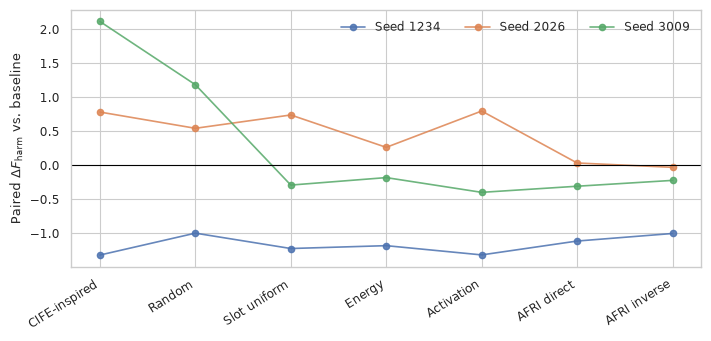

In [5]:
configurations = list(delta.columns)
x = np.arange(len(configurations))

fig, ax = plt.subplots(figsize=(7.2, 3.5))
for seed, row in delta.iterrows():
    ax.plot(
        x,
        row[configurations],
        marker="o",
        linewidth=1.2,
        markersize=4.5,
        alpha=0.85,
        label="Seed %s" % seed,
    )

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAMES.get(c, c) for c in configurations], rotation=32, ha="right")
ax.set_ylabel(r"Paired $\Delta F_{\mathrm{harm}}$ vs. baseline")
ax.set_xlabel("")
ax.legend(frameon=False, ncol=max(1, len(delta.index)))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "paired_seed_deltas.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "paired_seed_deltas.png", dpi=220, bbox_inches="tight")
plt.show()


## Silencing prevalence

Files already absent from a prediction CSV are no-op controls and are excluded from the eligible-intervention denominator.


In [6]:
interventions = silencing["interventions"]
subset_effects = silencing["subset_effects"]

assert subset_effects["condition_matches_observation"].all(), (
    "Analytical condition mismatches found",
    subset_effects.loc[~subset_effects["condition_matches_observation"]],
)

by_evaluator = evaluator_summary(interventions)
by_run = intervention_prevalence(interventions)

display(by_evaluator)
display(
    by_run.sort_values(
        ["evaluator_variant", "seed", "aggregate_improvements"],
        ascending=[True, True, False],
    )
)

by_evaluator.to_csv(TABLE_DIR / "silencing_by_evaluator.csv", index=False)
by_run.to_csv(TABLE_DIR / "silencing_by_run.csv", index=False)


,evaluator_variant,eligible_interventions,subset_improvements,aggregate_improvements,mean_delta_harmonic,max_delta_harmonic,subset_improvement_rate,aggregate_improvement_rate
0,corrected,995,302,301,-0.304359,1.935,0.303518,0.302513
1,released,995,285,284,-0.319682,1.896,0.286432,0.285427


,configuration,configuration_label,seed,evaluator_variant,eligible_interventions,subset_improvements,aggregate_improvements,mean_delta_harmonic,max_delta_harmonic,subset_improvement_rate,aggregate_improvement_rate
0,afri_direct,AFRI direct,1234,corrected,42,14,14,-0.280548,1.342,0.333333,0.333333
36,phase3_activation,Activation,1234,corrected,42,14,14,-0.312833,1.301,0.333333,0.333333
6,afri_inverse,AFRI inverse,1234,corrected,42,13,13,-0.302810,1.737,0.309524,0.309524
18,cife,CIFE-inspired,1234,corrected,41,13,13,-0.268220,1.098,0.317073,0.317073
24,phase1_random,Random,1234,corrected,42,13,13,-0.280357,1.623,0.309524,0.309524
42,slot_uniform,Slot uniform,1234,corrected,42,13,13,-0.271643,1.579,0.309524,0.309524
12,baseline,Baseline,1234,corrected,40,12,12,-0.344175,1.326,0.300000,0.300000
30,phase2_energy,Energy,1234,corrected,42,11,11,-0.262476,1.566,0.261905,0.261905
2,afri_direct,AFRI direct,2026,corrected,42,13,13,-0.274381,0.651,0.309524,0.309524
8,afri_inverse,AFRI inverse,2026,corrected,41,13,13,-0.327610,0.599,0.317073,0.317073


## Top interventions under the primary evaluator

Prefer a representative file that recurs across seeds/configurations over the single largest post-hoc gain.


In [7]:
eligible = interventions[~interventions["originally_silent"]].copy()
primary = eligible[eligible["evaluator_variant"] == PRIMARY_EVALUATOR].copy()

top_interventions = primary.sort_values(
    "delta_fmeasure_harmonic", ascending=False
)[[
    "configuration_label",
    "configuration",
    "seed",
    "target_filename",
    "affected_subsets",
    "predicted_events_removed",
    "predicted_duration_removed_seconds",
    "max_delta_affected_subset_f",
    "delta_fmeasure_harmonic",
    "delta_precision_harmonic",
    "delta_recall_harmonic",
    "improves_official",
]]

display(top_interventions.head(30))
top_interventions.head(50).to_csv(
    TABLE_DIR / ("top50_%s_interventions.csv" % PRIMARY_EVALUATOR),
    index=False,
)


,configuration_label,configuration,seed,target_filename,affected_subsets,predicted_events_removed,predicted_duration_removed_seconds,max_delta_affected_subset_f,delta_fmeasure_harmonic,delta_precision_harmonic,delta_recall_harmonic,improves_official
1855,AFRI direct,afri_direct,3009,BUK4_20161011_000804.wav,PB,276,71.912200,5.115727,1.935,1.822211,0.000000,True
1351,Baseline,baseline,3009,BUK4_20161011_000804.wav,PB,217,52.616417,5.722789,1.929,2.034128,0.000000,True
1939,AFRI inverse,afri_inverse,3009,BUK4_20161011_000804.wav,PB,245,63.599456,4.594626,1.806,1.723381,0.000000,True
1687,Energy,phase2_energy,3009,BUK4_20161011_000804.wav,PB,239,61.207800,4.717862,1.767,1.695364,0.000000,True
775,CIFE-inspired,cife,2026,ME1.wav,ME,298,101.459592,30.824829,1.755,2.297586,-0.254576,True
607,AFRI inverse,afri_inverse,1234,ME1.wav,ME,334,148.897959,44.036697,1.737,1.774947,-0.308987,True
1603,Slot uniform,slot_uniform,3009,BUK4_20161011_000804.wav,PB,232,61.556100,4.301673,1.644,1.549078,0.000000,True
187,Random,phase1_random,1234,ME1.wav,ME,326,141.688163,43.226443,1.623,1.683684,-0.342004,True
1771,Activation,phase3_activation,3009,BUK4_20161011_000804.wav,PB,231,61.927619,4.113004,1.616,1.515169,0.000000,True
271,Slot uniform,slot_uniform,1234,ME1.wav,ME,327,144.822857,42.748414,1.579,1.627197,-0.336867,True


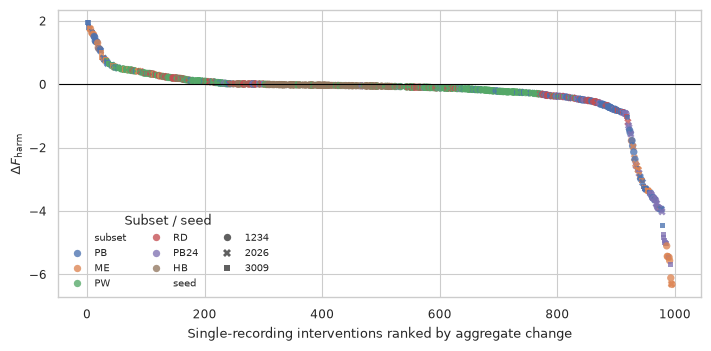

In [8]:
ranked = primary.sort_values(
    "delta_fmeasure_harmonic", ascending=False
).reset_index(drop=True)
ranked["rank"] = np.arange(1, len(ranked) + 1)
ranked["subset"] = ranked["affected_subsets"].astype(str).str.split(";").str[0]

fig, ax = plt.subplots(figsize=(7.2, 3.6))
sns.scatterplot(
    data=ranked,
    x="rank",
    y="delta_fmeasure_harmonic",
    hue="subset",
    style="seed",
    s=28,
    alpha=0.78,
    linewidth=0,
    ax=ax,
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Single-recording interventions ranked by aggregate change")
ax.set_ylabel(r"$\Delta F_{\mathrm{harm}}$")
ax.legend(title="Subset / seed", frameon=False, ncol=3, fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / ("ranked_%s_silencing_deltas.pdf" % PRIMARY_EVALUATOR), bbox_inches="tight")
fig.savefig(FIGURE_DIR / ("ranked_%s_silencing_deltas.png" % PRIMARY_EVALUATOR), dpi=220, bbox_inches="tight")
plt.show()


## Recording recurrence and heatmap

This identifies recordings whose aggregate-improving silence effect recurs across independently trained seeds or configurations.


,n_interventions,mean_delta,max_delta,n_aggregate_improvements,positive_seeds,positive_configurations
target_filename,,,,,,
ME1.wav,24,0.897333,1.755,24.0,3.0,8.0
pw5.wav,24,0.380833,0.518,24.0,3.0,8.0
pw2.wav,24,0.188292,0.508,24.0,3.0,8.0
pw6.wav,24,0.241542,0.500,24.0,3.0,8.0
RD_04.wav,24,0.228375,0.428,24.0,3.0,8.0
RD_01.wav,24,0.237042,0.420,24.0,3.0,8.0
pw1.wav,24,0.079917,0.123,24.0,3.0,8.0
RD_03.wav,24,0.009208,0.014,24.0,3.0,8.0
BUK4_20161011_000804.wav,23,1.194435,1.935,23.0,3.0,8.0


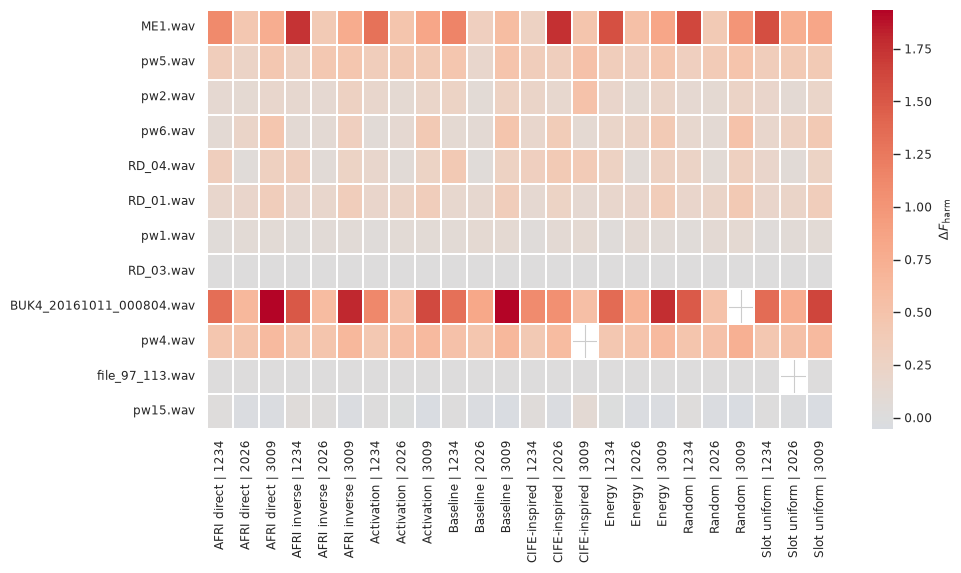

In [9]:
recurrence = recording_recurrence(interventions, PRIMARY_EVALUATOR)
display(recurrence.head(30))
recurrence.to_csv(TABLE_DIR / ("recording_recurrence_%s.csv" % PRIMARY_EVALUATOR))

top_files = list(recurrence.head(TOP_RECORDINGS).index)
heatmap_source = primary[primary["target_filename"].isin(top_files)].copy()
heatmap_source["run"] = (
    heatmap_source["configuration_label"]
    + " | "
    + heatmap_source["seed"].astype(str)
)
heatmap_data = heatmap_source.pivot_table(
    index="target_filename",
    columns="run",
    values="delta_fmeasure_harmonic",
    aggfunc="first",
).reindex(top_files)

fig_width = max(8.0, 0.42 * len(heatmap_data.columns))
fig, ax = plt.subplots(figsize=(fig_width, 0.36 * len(top_files) + 1.5))
sns.heatmap(
    heatmap_data,
    cmap="coolwarm",
    center=0,
    linewidths=0.25,
    cbar_kws={"label": r"$\Delta F_{\mathrm{harm}}$"},
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / ("recurring_file_heatmap_%s.pdf" % PRIMARY_EVALUATOR), bbox_inches="tight")
fig.savefig(FIGURE_DIR / ("recurring_file_heatmap_%s.png" % PRIMARY_EVALUATOR), dpi=220, bbox_inches="tight")
plt.show()


## Released versus corrected evaluator

Each point is the same configuration, seed, and target recording under the two evaluator variants.


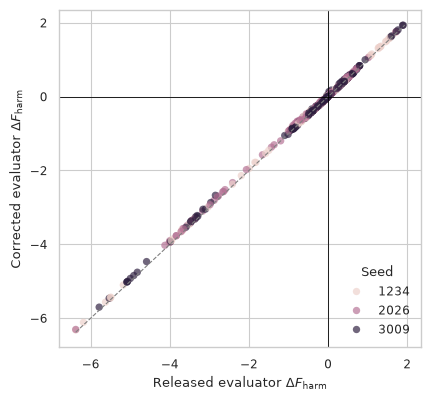

In [10]:
variant_comparison = interventions.pivot_table(
    index=["configuration", "configuration_label", "seed", "target_filename"],
    columns="evaluator_variant",
    values="delta_fmeasure_harmonic",
    aggfunc="first",
).reset_index()

if {"released", "corrected"}.issubset(variant_comparison.columns):
    fig, ax = plt.subplots(figsize=(4.4, 4.1))
    sns.scatterplot(
        data=variant_comparison,
        x="released",
        y="corrected",
        hue="seed",
        alpha=0.68,
        s=28,
        linewidth=0,
        ax=ax,
    )
    low = min(variant_comparison["released"].min(), variant_comparison["corrected"].min())
    high = max(variant_comparison["released"].max(), variant_comparison["corrected"].max())
    ax.plot([low, high], [low, high], "--", color="gray", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_xlabel(r"Released evaluator $\Delta F_{\mathrm{harm}}$")
    ax.set_ylabel(r"Corrected evaluator $\Delta F_{\mathrm{harm}}$")
    ax.legend(title="Seed", frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "released_vs_corrected.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "released_vs_corrected.png", dpi=220, bbox_inches="tight")
    plt.show()
else:
    print("Both evaluator variants are required for this plot.")


## Compact tables for paper drafting

These exports are intentionally plain. Format the final LaTeX tables manually for IEEE column width after deciding which columns survive the page limit.


In [11]:
paper_silence_summary = by_evaluator.copy()
paper_silence_summary["subset_improvement_pct"] = (
    100 * paper_silence_summary["subset_improvements"]
    / paper_silence_summary["eligible_interventions"]
)
paper_silence_summary["aggregate_improvement_pct"] = (
    100 * paper_silence_summary["aggregate_improvements"]
    / paper_silence_summary["eligible_interventions"]
)

display(paper_silence_summary)

paper_silence_summary.to_csv(
    TABLE_DIR / "paper_silencing_summary.csv", index=False
)
paper_silence_summary.to_latex(
    TABLE_DIR / "paper_silencing_summary.tex",
    index=False,
    float_format="%.3f",
)

conventional.to_latex(
    TABLE_DIR / "paper_conventional_summary.tex",
    index=False,
    float_format="%.3f",
)

print("Figures written to:", FIGURE_DIR)
print("Tables written to:", TABLE_DIR)


,evaluator_variant,eligible_interventions,subset_improvements,aggregate_improvements,mean_delta_harmonic,max_delta_harmonic,subset_improvement_rate,aggregate_improvement_rate,subset_improvement_pct,aggregate_improvement_pct
0,corrected,995,302,301,-0.304359,1.935,0.303518,0.302513,30.351759,30.251256
1,released,995,285,284,-0.319682,1.896,0.286432,0.285427,28.643216,28.542714


Figures written to: /home/nouransabry/workspace/Personal/Project_v2/baselines/dcase2024_task5/analysis/paper_outputs_three_seeds/figures
Tables written to: /home/nouransabry/workspace/Personal/Project_v2/baselines/dcase2024_task5/analysis/paper_outputs_three_seeds/tables
